# Stage 3 — Equivariant message passing with e3nn

The stage-3 counterpart of `gcn-from-scratch.ipynb`: build a minimal E(3)-equivariant message-passing layer in e3nn, then **prove** it is equivariant empirically.

**Checkpoint goals**
1. Rotation equivariance: `layer(rotate(x)) == rotate(layer(x))`, using the Wigner-D matrix for each output l
2. A deliberately broken baseline that the same test catches
3. Translation invariance
4. Reflections / parity: O(3) vs SO(3)
5. Float32 vs float64: what error size means "equivariant" and what means "bug"
6. Invariant energy readout, forces via autograd, and a check that the forces rotate as vectors

Versions verified 2026-10-08: **e3nn 0.6.0** (PyPI, docs.e3nn.org), torch 2.14 (CPU). `torch_cluster` and `torch_scatter` are not installed, so we build the radius graph and the neighbour sum by hand.

In [1]:
import torch
import e3nn
from e3nn import o3

torch.set_default_dtype(torch.float64)   # float64 while we test; we revisit float32 in the tolerance section
torch.manual_seed(0)
print("e3nn", e3nn.__version__, "| torch", torch.__version__)

e3nn 0.6.0 | torch 2.14.0+cu130


## 1. Irreps: type-l bookkeeping (Bekkers, Lecture 3.x)

In the lectures, a steerable feature is a stack of type-l vectors, each with 2l+1 components that rotate by the Wigner-D matrix D^l(R). `o3.Irreps` is exactly that list, plus one extra label, **parity**:

- `"8x0e"` means 8 channels of l=0, even parity: ordinary scalars (like energy)
- `"4x1o"` means 4 channels of l=1, odd parity: true vectors (like positions and forces)
- `"2x2e"` means 2 channels of l=2, even parity

The `8x` is the **multiplicity**, i.e. the number of channels. It plays the role that hidden size plays in your GCN. The features themselves are one flat tensor of shape `(N, irreps.dim)`. The `Irreps` object is metadata that says which slice of that tensor is which irrep.

In [2]:
irreps = o3.Irreps("8x0e + 4x1o + 2x2e")
print("irreps    :", irreps)
print("dim       :", irreps.dim, "  = 8*1 + 4*3 + 2*5")
print("num_irreps:", irreps.num_irreps, "  (sum of multiplicities)")
print("ls        :", irreps.ls)
print("slices    :", irreps.slices())

x = irreps.randn(5, -1)           # 5 nodes; -1 is replaced by irreps.dim
print("feature tensor:", x.shape)

irreps    : 8x0e+4x1o+2x2e
dim       : 30   = 8*1 + 4*3 + 2*5
num_irreps: 14   (sum of multiplicities)
ls        : [0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2]
slices    : [slice(0, 8, None), slice(8, 20, None), slice(20, 30, None)]
feature tensor: torch.Size([5, 30])


## 2. Wigner-D: one block-diagonal matrix for the whole feature

`irreps.D_from_matrix(R)` returns a `(dim, dim)` matrix with one D^l block per channel. So rotating a node's whole feature vector is one matmul, `x @ D.T`, which is the same row-vector convention as `pos @ R.T`.

Two checks that tie back to the lectures:
- `D` satisfies the representation property **D(R1) D(R2) = D(R1 R2)**
- For `1o`, e3nn's D is **R itself**. In e3nn 0.6.0, l=1 components are in (x, y, z) order (checked below, not assumed).

In [3]:
R1, R2 = o3.rand_matrix(), o3.rand_matrix()
D = irreps.D_from_matrix(R1)
print("D shape:", D.shape)

# block structure: nonzero only inside each irrep's slice
nonzero_blocks = (D.abs() > 1e-12).double()
print("off-block entries all zero:",
      all(nonzero_blocks[a, b].sum() == 0
          for i, a in enumerate(irreps.slices())
          for j, b in enumerate(irreps.slices()) if i != j))

# homomorphism: D(R1) D(R2) = D(R1 R2)
err = (irreps.D_from_matrix(R1) @ irreps.D_from_matrix(R2) - irreps.D_from_matrix(R1 @ R2)).abs().max()
print("D(R1)D(R2) - D(R1R2):", err.item())

# l=1 odd is the ordinary rotation matrix
print("D_1o(R) == R:", torch.allclose(o3.Irreps("1o").D_from_matrix(R1), R1))

D shape: torch.Size([30, 30])
off-block entries all zero: True
D(R1)D(R2) - D(R1R2): 4.218847493575595e-15
D_1o(R) == R: True


## 3. Parity: why `1o` and `1e` are different

Both `1o` and `1e` have the same D for proper rotations (det = +1). They only differ under **improper** transformations (det = -1), such as inversion `-I` or a mirror:
- `1o`, a true vector (position, force): flips sign under inversion
- `1e`, a pseudovector (angular momentum r × p, torque, magnetic field): does **not** flip

A rotation-only test cannot tell these two apart.

In [4]:
inv = -torch.eye(3)
mirror_z = torch.diag(torch.tensor([1.0, 1.0, -1.0]))

for name, g in [("rotation", R1), ("inversion", inv), ("mirror z", mirror_z)]:
    same = torch.allclose(o3.Irreps("1o").D_from_matrix(g), o3.Irreps("1e").D_from_matrix(g))
    print(f"{name:10s} det={torch.det(g).item():+.0f}   D_1o == D_1e ? {same}")

print("\nD_1o(-I):\n", o3.Irreps("1o").D_from_matrix(inv))
print("D_1e(-I):\n", o3.Irreps("1e").D_from_matrix(inv))

rotation   det=+1   D_1o == D_1e ? True
inversion  det=-1   D_1o == D_1e ? False
mirror z   det=-1   D_1o == D_1e ? False

D_1o(-I):
 tensor([[-1., -0., -0.],
        [-0., -1., -0.],
        [-0., -0., -1.]])
D_1e(-I):
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])


## 4. The CG tensor product, made concrete: 1o ⊗ 1o = 0e + 1e + 2e

Selection rules: |l1-l2| ≤ l ≤ l1+l2 from the lectures, **plus** output parity = p1·p2 (odd × odd = even).

For two vectors a, b the three outputs are familiar objects:
- **0e** is the dot product a·b
- **1e** is the cross product a×b, which is why it is a pseudovector
- **2e** is the traceless symmetric part of the outer product a bᵀ

`FullTensorProduct` has no learned weights: it is just the fixed CG coefficients. Below we check that its outputs match dot and cross up to e3nn's normalization constants.

In [5]:
tp = o3.FullTensorProduct("1o", "1o")
print(tp, "->", tp.irreps_out)

a, b = torch.randn(3), torch.randn(3)
out = tp(a, b)
s0, s1, s2 = [out[sl] for sl in tp.irreps_out.slices()]

print("0e / (a·b)  :", (s0 / (a @ b)).item())                 # constant: 1/sqrt(3)
print("1e / (a×b)  :", (s1 / torch.linalg.cross(a, b)).tolist())  # constant: 1/sqrt(2) for all 3 components
print("1/sqrt(3), 1/sqrt(2) =", 3**-0.5, 2**-0.5)

FullTensorProduct(1x1o x 1x1o -> 1x0e+1x1e+1x2e | 3 paths | 0 weights) -> 1x0e+1x1e+1x2e
0e / (a·b)  : 0.5773502691896257
1e / (a×b)  : [0.7071067811865475, 0.7071067811865476, 0.7071067811865475]
1/sqrt(3), 1/sqrt(2) = 0.5773502691896257 0.7071067811865476


/home/daniyusra/projects/manantara-playground/learning-habits/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


### Quiz (answer in chat before section 5)
1. `o3.Irreps("16x0e + 8x1o + 4x2e").dim` = ?
2. Your layer has hidden irreps `0e + 1o + 2e` only, and spherical-harmonic edge features. Name one tensor-product path that *would* produce a `0o` (pseudoscalar) if you asked for it. Why might a model of α-quartz (which has left- and right-handed forms) need one?
3. In section 2 we wrote `x @ D.T`. If a colleague writes `D @ x` on a feature tensor of shape `(N, dim)`, what happens? Is it just a shape error, or could it silently run and give a wrong answer?

### Quiz debrief: where does a pseudoscalar `0o` come from?

`1o ⊗ 1o` gives `0e + 1e + 2e`, which contains **no** `0o`, because odd × odd = even. In fact no *single* product of `0e`, `1o` and `2e` produces `0o`. It takes **two** steps:

    (1o ⊗ 1o → 1e)  then  (1e ⊗ 1o → 0o)        i.e.  a · (b × c)

That is the triple product, the signed volume of three edge vectors. It is the simplest chirality detector: it flips sign under a mirror image.

Physics note: **energy is `0e`**, and enantiomers (left- and right-handed quartz) have *identical* energy. So an E(3)-invariant energy model is *supposed* to give both the same value, and that is correct behaviour, not a missing feature. You need `0o` for **outputs** that distinguish handedness (a handedness label, optical activity), or as an intermediate feature that richer models carry.

In [6]:
cross = o3.FullTensorProduct("1o", "1o", filter_ir_out=["1e"])   # a × b   (pseudovector)
triple = o3.FullTensorProduct("1e", "1o", filter_ir_out=["0o"])  # (a×b) · c  (pseudoscalar)

a, b, c = torch.randn(3), torch.randn(3), torch.randn(3)
p = triple(cross(a, b), c)
print("0o / det[a,b,c]  :", (p / torch.det(torch.stack([a, b, c]))).item(), " (= 1/sqrt(6))")
print("original  :", p.item())
print("inverted  :", triple(cross(-a, -b), -c).item(), "  <- sign flips: a chirality signal")

0o / det[a,b,c]  : 0.4082482904638629  (= 1/sqrt(6))
original  : -0.06044821660462035
inverted  : 0.06044821660462035   <- sign flips: a chirality signal


## 5. Building the layer, piece 1: toy point cloud, radius graph, edge embedding

**Toy system:** one SiO₄ tetrahedron (Si–O bond ≈ 1.61 Å) with random jitter.

The jitter is not cosmetic. A *perfect* tetrahedron is symmetric, and equivariance then **forces** some outputs to be exactly zero. For example, a vector output on the central Si must vanish, because every symmetry of the tetrahedron has to leave it unchanged. A test that compares 0 with 0 passes even for a broken layer. **Always test on asymmetric inputs.**

**Radius graph:** we build it by hand (no `torch_cluster`), using the same `edge_index` convention as your PyG MPNN: `src = edge_index[0]` sends a message to `dst = edge_index[1]`.

In [7]:
def sio4(jitter=0.1):
    d = 1.61 / 3**0.5                      # tetrahedral vertices (±1,±1,±1) with an even number of minus signs, scaled to 1.61 Å
    o = d * torch.tensor([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]], dtype=torch.get_default_dtype())
    pos = torch.cat([torch.zeros(1, 3), o])
    return pos + jitter * torch.randn_like(pos)

def radius_graph(pos, r_max):
    dist = torch.cdist(pos, pos)
    mask = (dist < r_max) & ~torch.eye(len(pos), dtype=torch.bool)
    src, dst = mask.nonzero().T            # every ordered pair (j -> i) within the cutoff
    return src, dst

pos = sio4()
species = torch.tensor([0, 1, 1, 1, 1])    # 0 = Si, 1 = O
r_max = 3.0                                 # > O-O distance (~2.63 Å), so the graph here is fully connected
src, dst = radius_graph(pos, r_max)
edge_vec = pos[dst] - pos[src]
print("nodes:", len(pos), " edges:", len(src))
print("bond lengths (Si-O):", edge_vec[src == 0].norm(dim=1))

nodes: 5  edges: 20
bond lengths (Si-O): tensor([1.4037, 1.8162, 1.5834, 1.5720])


### Edge embedding = spherical harmonics of the edge direction

This is the "SH edge embedding" from your layer wiring. For every edge we compute `Y^l(r̂_ij)` for l = 0..lmax. These are the steerable *directions*. The *distance* is handled separately by the radial MLP (piece 2).

`normalization='component'` makes each component have mean square 1. The function's default is `'integral'`, and the tutorials override it, so we do too.

The cell below checks the single fact that makes the whole layer work: **Y(R r) = D(R) Y(r)**. It also answers quiz Q3 with a concrete failure.

In [8]:
lmax = 2
irreps_sh = o3.Irreps.spherical_harmonics(lmax)
print("irreps_sh:", irreps_sh, "  <- parity (-1)^l: an edge vector is a TRUE vector, so l=1 is odd")

sh = o3.spherical_harmonics(irreps_sh, edge_vec, normalize=True, normalization="component")
print("sh:", sh.shape, " mean square:", sh.pow(2).mean().item())
print("l=1 part / unit vector:", (sh[0, 1:4] / (edge_vec[0] / edge_vec[0].norm())).tolist(), "(= sqrt 3)")

R = o3.rand_matrix()
D_sh = irreps_sh.D_from_matrix(R)
sh_rot = o3.spherical_harmonics(irreps_sh, edge_vec @ R.T, normalize=True, normalization="component")

print("\nY(Rr) vs Y(r) @ D.T :", (sh_rot - sh @ D_sh.T).abs().max().item(), "  <- correct")
print("Y(Rr) vs Y(r) @ D   :", (sh_rot - sh @ D_sh).abs().max().item(), "  <- runs fine, silently wrong (applies R^-1)")

irreps_sh: 1x0e+1x1o+1x2e   <- parity (-1)^l: an edge vector is a TRUE vector, so l=1 is odd
sh: torch.Size([20, 9])  mean square: 1.0
l=1 part / unit vector: [1.7320508075688772, 1.7320508075688772, 1.7320508075688772] (= sqrt 3)

Y(Rr) vs Y(r) @ D.T : 6.328271240363392e-15   <- correct
Y(Rr) vs Y(r) @ D   : 0.9431290008501669   <- runs fine, silently wrong (applies R^-1)


**Quiz Q3 answer.** With `x` of shape `(N, dim)`:
- `D @ x` needs `dim == N`. Usually that is a shape error. But if your batch happens to have `N == dim` nodes (say 30 atoms and a 30-dim feature), it runs and **mixes features across different atoms**. That is silent garbage.
- The more realistic bug is `x @ D` instead of `x @ D.T`. It **always** runs, and because D is orthogonal it applies the *inverse* rotation. Your equivariance test then fails with an O(1) error, and you may waste an hour blaming the layer instead of the test.

Rule we'll use everywhere: **features are row vectors, so transform with `@ D.T`**, matching `pos @ R.T`.

**Next piece:** the radial MLP. Distances go to a smooth basis, then an MLP produces one weight per tensor-product path, per edge.

## 6. Building the layer, piece 2: radial MLP to per-edge path weights

**Why the radial MLP sees only |r|.** One edge's message is

    m_ij = Σ_paths  w_path · CG_path(x_j, Y(r̂_ij))

Under a rotation, each CG term is multiplied by D_out, and that is guaranteed by the fixed CG coefficients. So the whole message transforms correctly **only if every w_path is unchanged**, that is, invariant. Distance is invariant. Raw `edge_vec` is not.

**General rule:** anything that *multiplies* a steerable feature as a scalar must be `0e`. Examples are gate factors, radial weights, and attention coefficients in an equivariant GAT. The **direction** enters only through Y(r̂), which rotates correctly. Because the radial MLP acts on scalars, ReLU is fine inside it.

First we define the tensor product, so we know how many weights it needs. Piece 3 unpacks it properly.
- **Input node features:** one-hot species as `2x0e` (Si, O): invariant labels, like token IDs before the embedding.
- **Output:** `8x0e + 4x1o + 2x2e`.

In [9]:
from e3nn import nn as enn
from e3nn.math import soft_one_hot_linspace

irreps_in  = o3.Irreps("2x0e")
irreps_out = o3.Irreps("8x0e + 4x1o + 2x2e")
x_nodes = torch.nn.functional.one_hot(species, 2).to(torch.get_default_dtype())

# shared_weights=False: weights are passed in at call time, one row per edge
tp = o3.FullyConnectedTensorProduct(irreps_in, irreps_sh, irreps_out, shared_weights=False)
print(tp)
print("weights needed per edge:", tp.weight_numel, " (= 2*8 + 2*4 + 2*2: one per (in-channel, out-channel) pair on each path)")

FullyConnectedTensorProduct(2x0e x 1x0e+1x1o+1x2e -> 8x0e+4x1o+2x2e | 28 paths | 28 weights)
weights needed per edge: 28  (= 2*8 + 2*4 + 2*2: one per (in-channel, out-channel) pair on each path)


### Distance → smooth basis → MLP

`soft_one_hot_linspace` turns a distance into `num_basis` smooth bumps. It plays the role of a token embedding, but for a continuous scalar. With `cutoff=True` every bump goes to **0 at r_max**. Without that, an atom crossing the cutoff would make the energy jump, and the forces (dE/dx) would be undefined at that point.

NequIP itself uses a Bessel basis with a polynomial envelope. That is the same idea with a different basis; we'll meet it in the paper.

In [10]:
num_basis = 8

def radial_embedding(edge_vec):
    r = edge_vec.norm(dim=1)
    return soft_one_hot_linspace(r, start=0.0, end=r_max, number=num_basis,
                                 basis="smooth_finite", cutoff=True).mul(num_basis**0.5)

fc = enn.FullyConnectedNet([num_basis, 16, tp.weight_numel], torch.relu)

emb = radial_embedding(edge_vec)
w = fc(emb)
print("embedding:", emb.shape, "  weights:", w.shape, " (edges x tp.weight_numel)")
print("basis at r = r_max:", soft_one_hot_linspace(torch.tensor([r_max]), 0.0, r_max, num_basis,
                                                   basis="smooth_finite", cutoff=True).abs().max().item())

embedding: torch.Size([20, 8])   weights: torch.Size([20, 28])  (edges x tp.weight_numel)
basis at r = r_max: 0.0


### Demonstration: invariant weights vs a "direction-aware" MLP

Rotate the molecule and recompute the weights. The correct radial MLP gives identical weights. An MLP fed raw `edge_vec` gives different weights, so the CG paths get mixed differently and equivariance is broken. This is our **first broken baseline**, and it will reappear in the full test.

In [11]:
fc_bad = enn.FullyConnectedNet([3, 16, tp.weight_numel], torch.relu)   # sees direction: WRONG

R = o3.rand_matrix()
edge_vec_rot = edge_vec @ R.T

good = (fc(radial_embedding(edge_vec_rot)) - fc(radial_embedding(edge_vec))).abs().max()
bad  = (fc_bad(edge_vec_rot) - fc_bad(edge_vec)).abs().max()
print(f"radial MLP(|r|)      weight change under rotation: {good.item():.1e}   <- invariant")
print(f"MLP(edge_vec)        weight change under rotation: {bad.item():.1e}   <- not invariant: will break equivariance")

radial MLP(|r|)      weight change under rotation: 6.2e-15   <- invariant
MLP(edge_vec)        weight change under rotation: 7.4e+00   <- not invariant: will break equivariance


## 7. Building the layer, piece 3: per-edge tensor product, neighbour sum, first full test

**Why the sum preserves equivariance:** every message into node i transforms by the *same* D_out, and D_out factors out of a linear sum:

    Σ_j D_out m_ij  =  D_out Σ_j m_ij

Permutation invariance (the stage-1 GNN property) is a *different* symmetry: it is about the order of neighbours, not about rotating space. Mean aggregation is fine, since the count is invariant. **Component-wise max (GraphSAGE max-pool) is not**, because the largest x-component depends on which way you point the axes.

The whole layer, in your MPNN vocabulary:
- **message:** `tp(x[src], Y(r̂), w(|r|))`
- **aggregate:** `index_add_` over `dst`, divided by √(avg #neighbours) (the Normalization tutorial explains why)
- **update:** none yet (piece 4 adds the gate and a self-interaction)

In [12]:
def conv(pos, x, weights_fn=None, aggr="sum", avg_num_neighbors=4.0):
    src, dst = radius_graph(pos, r_max)
    vec = pos[dst] - pos[src]
    sh = o3.spherical_harmonics(irreps_sh, vec, normalize=True, normalization="component")
    w = weights_fn(vec) if weights_fn is not None else fc(radial_embedding(vec))
    msg = tp(x[src], sh, w)                                         # (E, irreps_out.dim)
    out = torch.zeros(len(pos), irreps_out.dim, dtype=msg.dtype)
    if aggr == "sum":
        out = out.index_add(0, dst, msg)
    elif aggr == "max":                                              # GraphSAGE-style max-pool, component-wise
        out = out.scatter_reduce(0, dst[:, None].expand_as(msg), msg, reduce="amax", include_self=False)
    return out / avg_num_neighbors**0.5

h = conv(pos, x_nodes)
print("output:", h.shape, "=", irreps_out)

output: torch.Size([5, 30]) = 8x0e+4x1o+2x2e


### The rotation test

The layer passes if `conv(rotate(input))` equals `rotate(conv(input))`:
- **input side:** positions use `pos @ R.T`, features use `x @ D_in.T` (our input is `2x0e`, so D_in is the identity, but we write it out anyway)
- **output side:** `h @ D_out.T`, where `D_out` is block-diagonal with the correct Wigner-D for **each output irrep**

We also report the error **per output irrep**. When something breaks, *which* l breaks tells you a lot about the cause.

In [13]:
def rotation_error(f, R=None):
    R = o3.rand_matrix() if R is None else R
    D_in, D_out = irreps_in.D_from_matrix(R), irreps_out.D_from_matrix(R)
    diff = f(pos @ R.T, x_nodes @ D_in.T) - f(pos, x_nodes) @ D_out.T
    per_irrep = {str(mul_ir): diff[:, sl].abs().max().item()
                 for mul_ir, sl in zip(irreps_out, irreps_out.slices())}
    return diff.abs().max().item(), per_irrep

def report(name, f):
    err, per = rotation_error(f)
    print(f"{name:28s} max err {err:.1e}   " + "  ".join(f"{k}: {v:.0e}" for k, v in per.items()))

report("correct layer", conv)
report("BROKEN: MLP(edge_vec)", lambda p, x: conv(p, x, weights_fn=fc_bad))
report("BROKEN: max aggregation", lambda p, x: conv(p, x, aggr="max"))

correct layer                max err 3.5e-15   8x0e: 3e-15  4x1o: 3e-15  2x2e: 3e-15


BROKEN: MLP(edge_vec)        max err 8.6e+00   8x0e: 5e+00  4x1o: 9e+00  2x2e: 2e+00
BROKEN: max aggregation      max err 1.2e+00   8x0e: 1e-15  4x1o: 1e+00  2x2e: 1e+00


**Reading the per-irrep breakdown:**
- **MLP(edge_vec)** breaks *every* irrep, including `0e`. The weights themselves changed, so even the scalar outputs change.
- **Max aggregation** leaves `0e` intact, since the max of invariant scalars is still invariant, but it breaks `1o` and `2e`. A rule of thumb: *if only l > 0 fails, look for a nonlinearity or reduction applied component-wise to steerable features.*

## 8. Building the layer, piece 4: gate, self-interaction, two layers

**Gate bookkeeping:** one `0e` gate per **gated channel**, so `4x1o + 2x2e` needs `6x0e` gates. Each gate scales a whole channel (all 2l+1 components by the same factor), which commutes with D. A per-component gate would act like ReLU and break equivariance. e3nn enforces the count (verified in 0.6.0: a mismatch raises `ValueError`).

`gate.irreps_in` = `8x0e` (scalars, activated) + `6x0e` (gates, sigmoid) + `4x1o+2x2e` (gated). So the conv must output **that layout**, and the gate turns it into `8x0e + 4x1o + 2x2e`.

**Self-interaction** is `o3.Linear`, a per-node channel mixer *within* each irrep type: 0e with 0e, 1o with 1o, never across l. Think of it as the 1×1 conv, or the W·h_i self-term in your GCN. NequIP uses this name for it.

Block: `h = Gate( Conv(x) + SelfInteraction(x) )`.

We now turn the conv into a `torch.nn.Module`, the way your GAT went from a function to a layer.

In [14]:
class Conv(torch.nn.Module):
    def __init__(self, irreps_in, irreps_out, num_basis=8, hidden=16, avg_num_neighbors=4.0):
        super().__init__()
        self.irreps_in, self.irreps_out = o3.Irreps(irreps_in), o3.Irreps(irreps_out)
        self.tp = o3.FullyConnectedTensorProduct(self.irreps_in, irreps_sh, self.irreps_out, shared_weights=False)
        self.fc = enn.FullyConnectedNet([num_basis, hidden, self.tp.weight_numel], torch.relu)
        self.avg_num_neighbors = avg_num_neighbors

    def forward(self, pos, x, src, dst):
        vec = pos[dst] - pos[src]
        sh = o3.spherical_harmonics(irreps_sh, vec, normalize=True, normalization="component")
        msg = self.tp(x[src], sh, self.fc(radial_embedding(vec)))
        out = torch.zeros(len(pos), self.irreps_out.dim, dtype=msg.dtype).index_add(0, dst, msg)
        return out / self.avg_num_neighbors**0.5


class Block(torch.nn.Module):
    # act="gate": correct.  act="relu": BROKEN baseline, plain ReLU on every component (including l>0)
    def __init__(self, irreps_in, scalars="8x0e", gated="4x1o + 2x2e", act="gate"):
        super().__init__()
        gated = o3.Irreps(gated)
        self.gate = enn.Gate(scalars, [torch.nn.functional.silu],
                             f"{gated.num_irreps}x0e", [torch.sigmoid], gated)
        self.act = act
        self.irreps_out = self.gate.irreps_out
        pre = self.gate.irreps_in if act == "gate" else self.irreps_out   # relu variant needs no gate scalars
        self.conv = Conv(irreps_in, pre)
        self.self_int = o3.Linear(irreps_in, pre)

    def forward(self, pos, x, src, dst):
        h = self.conv(pos, x, src, dst) + self.self_int(x)
        return self.gate(h) if self.act == "gate" else torch.relu(h)


class TinyNet(torch.nn.Module):
    def __init__(self, act="gate", irreps_in="2x0e"):
        super().__init__()
        self.b1 = Block(irreps_in, act=act)
        self.b2 = Block(self.b1.irreps_out, act=act)
        self.irreps_out = self.b2.irreps_out

    def forward(self, pos, x):
        src, dst = radius_graph(pos, r_max)
        return self.b2(pos, self.b1(pos, x, src, dst), src, dst)


net = TinyNet()
print("block 1 gate.irreps_in:", net.b1.gate.irreps_in, "->", net.b1.irreps_out)
print("block 2 tensor product:", net.b2.conv.tp)
print("output:", net(pos, x_nodes).shape)

block 1 gate.irreps_in: 14x0e+4x1o+2x2e -> 8x0e+4x1o+2x2e
block 2 tensor product: FullyConnectedTensorProduct(8x0e+4x1o+2x2e x 1x0e+1x1o+1x2e -> 14x0e+4x1o+2x2e | 300 paths | 300 weights)
output: torch.Size([5, 30])


Layer 2's tensor product has inputs `0e + 1o + 2e` on *both* sides, so it contains genuinely geometric paths, such as `1o ⊗ 1o → 0e` (a dot product of a learned vector with the edge direction) and `2e ⊗ 1o → 1o`. Layer 1 could only scale the spherical harmonics by scalar features.

### Same test, now through two layers with nonlinearities

In [15]:
def equiv_report(name, f, irreps_out, R=None):
    R = o3.rand_matrix() if R is None else R
    D_in, D_out = irreps_in.D_from_matrix(R), irreps_out.D_from_matrix(R)
    diff = f(pos @ R.T, x_nodes @ D_in.T) - f(pos, x_nodes) @ D_out.T
    per = "  ".join(f"{mi}: {diff[:, sl].abs().max().item():.0e}" for mi, sl in zip(irreps_out, irreps_out.slices()))
    print(f"{name:26s} max err {diff.abs().max().item():.1e}   {per}")

net_relu = TinyNet(act="relu")
equiv_report("TinyNet (gate)", net, net.irreps_out)
equiv_report("BROKEN: TinyNet (ReLU)", net_relu, net_relu.irreps_out)

TinyNet (gate)             max err 7.8e-15   8x0e: 5e-15  4x1o: 8e-15  2x2e: 4e-15
BROKEN: TinyNet (ReLU)     max err 5.4e-01   8x0e: 4e-02  4x1o: 1e-01  2x2e: 5e-01


**What the ReLU failure looks like.** In layer 1, ReLU breaks only the `1o`/`2e` outputs, the same "only l>0" signature as max aggregation. Layer 2 then *mixes* those corrupted vectors into its scalars through paths like `1o ⊗ 1o → 0e`, so by the output **even `0e` is wrong**. That is why we test the **final** output and also each block on its own: an error in one block spreads through everything after it.

In [16]:
# localise: test block 1 alone, for both variants
for name, m in [("block1 (gate)", net), ("BROKEN: block1 (ReLU)", net_relu)]:
    equiv_report(name, lambda p, x, m=m: m.b1(p, x, *radius_graph(p, r_max)), m.b1.irreps_out)

block1 (gate)              max err 1.1e-14   8x0e: 4e-15  4x1o: 7e-15  2x2e: 1e-14
BROKEN: block1 (ReLU)      max err 8.1e-01   8x0e: 8e-16  4x1o: 8e-01  2x2e: 6e-01


## 9. How to read the numbers: round-off vs bug

An equivariance error is never exactly 0, because floating point rounds. The question is **how big it is compared with the outputs**:

- **float64 machine epsilon ≈ 2.2e-16.** A few hundred floating-point operations accumulate this to roughly **1e-15 to 1e-13**. That is round-off, meaning *equivariant*.
- The outputs themselves are of size **~1** (e3nn's normalization aims for that).
- A real bug produces an error **comparable to the outputs**: 1e-2 to 1e+1.

So the correct and broken cases are not "slightly different". They are separated by **~12 orders of magnitude**. Look at the **exponent**: `e-15` passes, `e-01` fails. Below we turn that into a relative error and a PASS/FAIL verdict, and plot it.

### Why ReLU *must* fail: a hand-checkable example
Take v = (1, -1, 0) and R = 90° rotation about z, so (x, y) → (-y, x):

In [17]:
v = torch.tensor([1.0, -1.0, 0.0])
Rz = torch.tensor([[0.0, -1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
print("ReLU(R v) =", torch.relu(Rz @ v).tolist())    # rotate first: (1, 1, 0) -> ReLU keeps it
print("R ReLU(v) =", (Rz @ torch.relu(v)).tolist())  # ReLU first: (1, 0, 0) -> rotate -> (0, 1, 0)
print("Same vector? ", torch.allclose(torch.relu(Rz @ v), Rz @ torch.relu(v)))

ReLU(R v) = [1.0, 1.0, 0.0]
R ReLU(v) = [0.0, 1.0, 0.0]
Same vector?  False


ReLU zeroes whichever components happen to be negative *in this coordinate frame*. Rotate the frame, and different components are negative, so the result depends on the frame. That is the definition of not equivariant.

By contrast, the gate multiplies the whole vector by sigmoid(scalar). Scaling a vector commutes with rotating it, and the scalar is invariant, so the gate is equivariant.

PASS   1.4e-15  conv (correct)
FAIL   1.7e+00  conv, MLP(edge_vec)
FAIL   1.9e+00  conv, max aggregation
PASS   4.5e-15  TinyNet, gate (correct)
FAIL   6.7e-01  TinyNet, ReLU


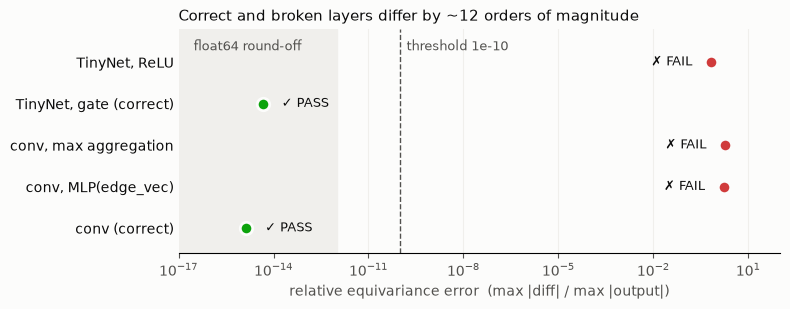

In [18]:
import matplotlib.pyplot as plt

def rel_error(f, irreps_out, R):
    D_in, D_out = irreps_in.D_from_matrix(R), irreps_out.D_from_matrix(R)
    out = f(pos, x_nodes)
    diff = f(pos @ R.T, x_nodes @ D_in.T) - out @ D_out.T
    return (diff.abs().max() / out.abs().max()).item()

R = o3.rand_matrix()
cases = [
    ("conv (correct)",            conv,                                       irreps_out),
    ("conv, MLP(edge_vec)",       lambda p, x: conv(p, x, weights_fn=fc_bad), irreps_out),
    ("conv, max aggregation",     lambda p, x: conv(p, x, aggr="max"),        irreps_out),
    ("TinyNet, gate (correct)",   net,                                        net.irreps_out),
    ("TinyNet, ReLU",             net_relu,                                   net_relu.irreps_out),
]
TOL = 1e-10   # float64 threshold; section 12 explains where this comes from
results = [(name, rel_error(f, ir, R)) for name, f, ir in cases]
for name, e in results:
    print(f"{'PASS' if e < TOL else 'FAIL'}  {e:8.1e}  {name}")

# chart: one dot per test on a log axis. The distance between the groups is the whole point.
GOOD, CRITICAL, INK, MUTED, BAND = "#0ca30c", "#d03b3b", "#0b0b0b", "#52514e", "#f0efec"
fig, ax = plt.subplots(figsize=(8, 3.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.axvspan(1e-17, 1e-12, color=BAND, zorder=0)
ax.text(3e-17, len(results) - 0.45, "float64 round-off", color=MUTED, fontsize=9, va="top")
ax.axvline(TOL, color=MUTED, lw=1, ls="--", zorder=1)
ax.text(TOL * 1.6, len(results) - 0.45, f"threshold {TOL:.0e}", color=MUTED, fontsize=9, va="top")
for i, (name, e) in enumerate(results):
    ok = e < TOL
    ax.scatter(e, i, s=80, color=GOOD if ok else CRITICAL, edgecolor="#fcfcfb", linewidth=2, zorder=3)
    ax.text(e * (4 if ok else 0.25), i, ("✓ PASS" if ok else "✗ FAIL"), color=INK, fontsize=9,
            va="center", ha="left" if ok else "right")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e2); ax.set_ylim(-0.6, len(results) - 0.2)
ax.set_yticks(range(len(results)), [n for n, _ in results], color=INK)
ax.set_xlabel("relative equivariance error  (max |diff| / max |output|)", color=MUTED)
ax.set_title("Correct and broken layers differ by ~12 orders of magnitude", color=INK, loc="left", fontsize=11)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", colors=MUTED)
ax.grid(axis="x", color=BAND, lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 10. Translation invariance

For E(3) = R³ ⋊ O(3), the translation part acts trivially on all our features: they are built from `pos[dst] - pos[src]`, and (x_i + t) - (x_j + t) = x_i - x_j. So **every** output irrep should be *unchanged* by a translation. There is no D to apply; the expected transform is the identity.

Two broken baselines:
1. **`pos` appended as a `1o` feature.** `pos` really does rotate like `1o` about the origin, so the **rotation test passes**, but the translation test fails. Rotating about any other point is a rotation plus a translation, so it would fail too. A molecule has no special origin.
2. **Raw coordinates into a plain MLP** (no irreps, positions treated as 3 independent numbers). This fails **both**.

In [19]:
def rel_trans_error(f, t):
    out = f(pos, x_nodes)
    return ((f(pos + t, x_nodes) - out).abs().max() / out.abs().max()).item()

# baseline 1: pos as a 1o input feature
net_pos = TinyNet(irreps_in="2x0e + 1x1o")
f_pos = lambda p, x: net_pos(p, torch.cat([x, p], dim=1))

# baseline 2: plain MLP on [one-hot, xyz] per atom, output read as if it were irreps_out
mlp = torch.nn.Sequential(torch.nn.Linear(5, 32), torch.nn.SiLU(), torch.nn.Linear(32, irreps_out.dim))
f_mlp = lambda p, x: mlp(torch.cat([x, p], dim=1))

R, t = o3.rand_matrix(), 2.0 * torch.randn(3)
print(f"{'':28s} {'rotation':>10s} {'translation':>12s}")
for name, f, ir in [("TinyNet (correct)", net, net.irreps_out),
                    ("BROKEN: pos as 1o feature", f_pos, net_pos.irreps_out),
                    ("BROKEN: MLP on raw xyz", f_mlp, irreps_out)]:
    er, et = rel_error(f, ir, R), rel_trans_error(f, t)
    v = lambda e: f"{e:.0e} {'PASS' if e < TOL else 'FAIL'}"
    print(f"{name:28s} {v(er):>10s} {v(et):>12s}")

                               rotation  translation
TinyNet (correct)            3e-15 PASS   2e-15 PASS
BROKEN: pos as 1o feature    1e-15 PASS   1e+00 FAIL
BROKEN: MLP on raw xyz       1e+00 FAIL   1e+00 FAIL


**Lesson for test design:** a rotation-only test would have **passed** baseline 1. Each symmetry needs its own test. In section 11, parity is the same story: a test that uses only proper rotations (det = +1) can never catch a parity bug.

## 11. Reflections and parity: O(3) vs SO(3)

Every improper transformation (det = -1) is a rotation times inversion. So **rotation test + inversion test** covers all of O(3). `D_from_matrix` accepts det = -1 matrices directly and applies the parity sign p^k to each irrep.

Why TinyNet passes: inputs are `0e` and edge spherical harmonics are `0e + 1o + 2e`. e3nn only creates tensor-product paths that obey output parity = p1·p2, and the gate uses `0e` gates. So every label is honest, and the network is O(3)-equivariant **by construction**.

Not having `0o` does not break equivariance. It limits what the model can **express**: TinyNet cannot tell a structure from its mirror image. For energy that is physically correct, because enantiomers have equal energy.

In [20]:
inversion = -torch.eye(3)
improper = o3.rand_matrix() @ inversion            # a random reflection-type transformation, det = -1
print("det:", torch.det(improper).item())

for name, g in [("rotation", o3.rand_matrix()), ("inversion", inversion), ("rotation x inversion", improper)]:
    e = rel_error(net, net.irreps_out, g)
    print(f"TinyNet  {name:22s} {e:.0e}  {'PASS' if e < TOL else 'FAIL'}")

det: -1.0
TinyNet  rotation               4e-15  PASS
TinyNet  inversion              0e+00  PASS
TinyNet  rotation x inversion   4e-15  PASS


### The mislabelling bug: same network, wrong labels

Take the *same* outputs but declare the vectors as `4x1e` instead of `4x1o`, which is the "forces labelled as pseudovectors" mistake. The rotation test cannot see it, because D_1e = D_1o for det = +1. The inversion test catches it.

In [21]:
wrong_labels = o3.Irreps("8x0e + 4x1e + 2x2e")     # same dims, wrong parity on the vectors
for name, g in [("rotation", o3.rand_matrix()), ("rotation x inversion", improper)]:
    e = rel_error(net, wrong_labels, g)
    print(f"mislabelled 1e  {name:22s} {e:.0e}  {'PASS' if e < TOL else 'FAIL'}")

mislabelled 1e  rotation               3e-15  PASS
mislabelled 1e  rotation x inversion   2e+00  FAIL


### Why the wrong label is *physically* wrong, not just a test failure

Suppose the network *really* produces a `1e` (pseudovector) output. On a **planar** configuration (all atoms in z = 0, symmetric under the mirror z → -z), equivariance forces:
- a true vector `1o` on each atom to lie **in the plane** (z-component = 0)
- a pseudovector `1e` to point **perpendicular** to the plane (x, y components = 0)

Forces on a planar molecule lie in the plane. A `1e` "force head" could only output the perpendicular direction, **for any weights**, so training could never fix it. Below, one network has both `1o` and `1e` outputs, and we look at their directions on a planar input.

In [22]:
b1 = Block("2x0e", gated="4x1o + 4x1e + 2x2e")
b2 = Block(b1.irreps_out, gated="4x1o + 4x1e + 2x2e")

pos_planar = torch.cat([torch.randn(5, 2), torch.zeros(5, 1)], dim=1)   # 5 atoms in the z = 0 plane
s, d = radius_graph(pos_planar, r_max)
h = b2(pos_planar, b1(pos_planar, x_nodes, s, d), s, d)

for mul_ir, sl in zip(b2.irreps_out, b2.irreps_out.slices()):
    if mul_ir.ir.l == 1:
        v = h[:, sl].reshape(len(pos_planar), mul_ir.mul, 3)
        print(f"{str(mul_ir):5s}  max |in-plane x,y| = {v[..., :2].abs().max().item():.1e}"
              f"   max |out-of-plane z| = {v[..., 2].abs().max().item():.1e}")
print("edges:", len(s))

4x1o   max |in-plane x,y| = 7.5e+00   max |out-of-plane z| = 0.0e+00
4x1e   max |in-plane x,y| = 0.0e+00   max |out-of-plane z| = 1.9e+00
edges: 16


### Cross-check with e3nn's own tester

`e3nn.util.test.equivariance_error` (verified in 0.6.0) tests rotations, with and without parity, and with and without translation, transforming in float64. `'cartesian_points'` tells it the first argument is a set of positions, which get rotated *and* translated. Keys are `(parity_k, did_translation)`.

In [23]:
from e3nn.util.test import equivariance_error

for name, f, ir_out in [("TinyNet", net, net.irreps_out),
                        ("mislabelled 1e", net, wrong_labels),
                        ("pos as 1o feature", f_pos, net_pos.irreps_out)]:
    errs = equivariance_error(f, [pos, x_nodes], irreps_in=["cartesian_points", irreps_in], irreps_out=[ir_out])
    print(f"{name:18s}", "  ".join(f"(p={k[0]},t={int(k[1])}): {v.max().item():.0e}" for k, v in errs.items()))

TinyNet            (p=0,t=0): 2e-14  (p=0,t=1): 2e-14  (p=1,t=0): 4e-15  (p=1,t=1): 1e-14
mislabelled 1e     (p=0,t=0): 1e-14  (p=0,t=1): 2e-14  (p=1,t=0): 4e+00  (p=1,t=1): 4e+00


pos as 1o feature  (p=0,t=0): 3e-14  (p=0,t=1): 1e+02  (p=1,t=0): 2e-14  (p=1,t=1): 1e+02


## 12. Float32 vs float64: what counts as "equivariant"?

Round-off error scales with machine epsilon:

| dtype | eps | expected error for a correct net | e3nn's default tolerance (`e3nn/util/test.py`, 0.6.0) |
|---|---|---|---|
| float64 | 2.2e-16 | ~1e-15 to 1e-13 | 1e-9 |
| float32 | 1.2e-7 | ~1e-7 to 1e-5 | 1e-3 |

e3nn's defaults are deliberately loose, giving about 4 to 6 orders of headroom over round-off, because error grows with depth, feature size and number of neighbours.

**The most useful diagnostic:** run the same test in both precisions.
- **Round-off** shrinks by ~1e8 to 1e9 when you go from float32 to float64.
- **A bug does not change at all**, because it is a property of the math and not of the rounding.

Method: run the *model* in each dtype, but always build R and the D matrices in **float64** and compare in float64, so we measure the model's error and not the test's own (e3nn's tester does the same via `transform_dtype=torch.float64`). We use 100 random rotations and reflections to look at the spread, not one lucky sample.

In [24]:
import copy

def rel_error_dtype(model, irreps_out, dtype, n_trials=100, D_fn=lambda ir, R: ir.D_from_matrix(R)):
    m = copy.deepcopy(model).to(dtype)
    p, x = pos.to(dtype), x_nodes.to(dtype)
    errs = []
    for k in range(n_trials):
        R = o3.rand_matrix(dtype=torch.float64) * (-1 if k % 2 else 1)   # alternate proper / improper
        D_out = D_fn(irreps_out, R)
        out = m(p, x).double()
        out_rot_in = m((pos @ R.T).to(dtype), x).double()               # rotate in float64, then cast
        errs.append(((out_rot_in - out @ D_out.T).abs().max() / out.abs().max()).item())
    return torch.tensor(errs)

table = {}
for name, model in [("TinyNet (gate)", net), ("BROKEN: TinyNet (ReLU)", net_relu)]:
    for dtype in [torch.float32, torch.float64]:
        e = rel_error_dtype(model, model.irreps_out, dtype)
        table[(name, str(dtype)[6:])] = e
        print(f"{name:24s} {str(dtype)[6:]:8s} median {e.median():.1e}   max {e.max():.1e}")

TinyNet (gate)           float32  median 1.5e-06   max 2.7e-06


TinyNet (gate)           float64  median 3.9e-15   max 1.8e-11


BROKEN: TinyNet (ReLU)   float32  median 6.9e-01   max 9.4e-01


BROKEN: TinyNet (ReLU)   float64  median 7.0e-01   max 9.3e-01


**Reading it:**
- The correct net's error drops by ~1e8 when going from float32 to float64. That is round-off.
- The ReLU net's error is the **same** in both dtypes. That is a bug.
- Even in float32, correct and broken are ~4 to 5 orders of magnitude apart, so float32 is perfectly usable for *training*. Just test with a float32 threshold, or test in float64.

**Rule of thumb for your team:** an error that *scales with eps* is round-off. An error that *does not change with dtype* is a bug. An error that is "in between", such as 1e-4 in float64, deserves a look. Common causes are a near-zero edge length (r̂ = r/|r| blows up when two atoms nearly overlap) or a non-smooth cutoff.

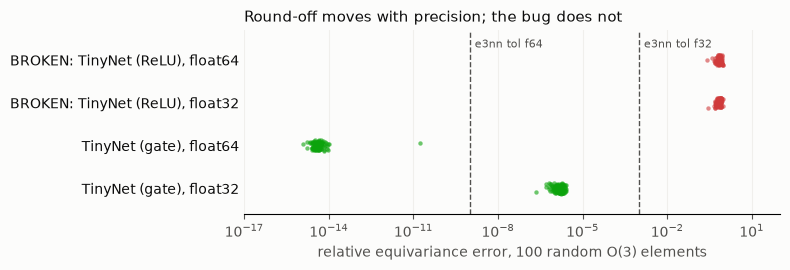

In [25]:
fig, ax = plt.subplots(figsize=(8, 2.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
rows = list(table.items())
for i, ((name, dt), e) in enumerate(rows):
    ok = name.startswith("TinyNet (gate)")
    ax.scatter(e, torch.full_like(e, i) + 0.25 * (torch.rand_like(e) - 0.5), s=10,
               color=GOOD if ok else CRITICAL, alpha=0.6, linewidth=0)
for tol, lbl in [(1e-9, "e3nn tol f64"), (1e-3, "e3nn tol f32")]:
    ax.axvline(tol, color=MUTED, lw=1, ls="--")
    ax.text(tol * 1.5, len(rows) - 0.5, lbl, color=MUTED, fontsize=8, va="top")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e2); ax.set_ylim(-0.6, len(rows) - 0.3)
ax.set_yticks(range(len(rows)), [f"{n}, {d}" for (n, d), _ in rows], color=INK)
ax.set_xlabel("relative equivariance error, 100 random O(3) elements", color=MUTED)
ax.set_title("Round-off moves with precision; the bug does not", color=INK, loc="left", fontsize=11)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", colors=MUTED)
ax.grid(axis="x", color=BAND, lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### An "in between" error, found for real: float64 outliers at ~1e-11

Look at the float64 row for the correct net: the median is ~4e-15, but the **max is ~2e-11**, about 1% of trials sitting 3 to 4 orders above round-off. It is still under e3nn's 1e-9 tolerance, but it deserves an explanation. Bisecting (done offline, summarised here):

1. It already appears in **block 1's conv**, not in deeper layers.
2. Radial weights: fine (~1e-14). Spherical harmonics: exact (4e-16 against √3 · r/|r|). `pos @ R.T`: exact.
3. The culprit is the **test's own D matrix**. e3nn's `wigner_D` is built from `torch.matrix_exp(angle * generator)`. In torch 2.14 (CPU, float64), `matrix_exp` on a **single** matrix (or a batch of 1) is only accurate to ~2e-10 when the angle is small (~0.02 to 0.05 rad). On a **batch of ≥2** it is accurate to ~1e-14.

So the layer was fine. The **ruler** was slightly bent. Below is the evidence, then the fix: compute D for `[R, I]` as a batch and take element 0.

In [26]:
X = o3.so3_generators(1)
theta = torch.rand(5000) * 0.1                         # small angles, where the problem shows up
A = theta[:, None, None] * X[1]
batched = torch.matrix_exp(A)
single  = torch.stack([torch.matrix_exp(a) for a in A])
print(f"matrix_exp single vs batched, max diff: {(single - batched).abs().max().item():.1e}")

def D_of(irreps, R):
    # batch with the identity so torch takes the accurate batched matrix_exp path
    return irreps.D_from_matrix(torch.stack([R, torch.eye(3, dtype=R.dtype)]))[0]

Rs = o3.rand_matrix(2000)
ir1 = o3.Irreps("1o")                                   # D_1o(R) must equal R exactly
print(f"D_1o vs R, single R : {max((ir1.D_from_matrix(R) - R).abs().max().item() for R in Rs):.1e}")
print(f"D_1o vs R, D_of     : {max((D_of(ir1, R) - R).abs().max().item() for R in Rs):.1e}")

matrix_exp single vs batched, max diff: 2.5e-10


D_1o vs R, single R : 2.3e-10


D_1o vs R, D_of     : 7.5e-15


In [27]:
for dtype in [torch.float32, torch.float64]:
    e = rel_error_dtype(net, net.irreps_out, dtype, D_fn=D_of)
    print(f"TinyNet (gate), D_of   {str(dtype)[6:]:8s} median {e.median():.1e}   max {e.max():.1e}")

TinyNet (gate), D_of   float32  median 1.4e-06   max 3.1e-06


TinyNet (gate), D_of   float64  median 3.9e-15   max 1.2e-14


**Lessons:**
- An error in the gap between round-off and a bug is a signal. Bisect it **including the test harness**, not just the model.
- Test with **many** random group elements and look at the **max**, not one sample. A single random R would have hidden this ~99% of the time.
- e3nn's own tester and tolerance (1e-9) absorb this outlier, which is why it does not cause failures in practice. I have not checked whether other torch versions behave the same way, so treat this as specific to torch 2.14 on CPU.

## 13. Energy readout and forces via autograd

**Readout:** a per-atom `o3.Linear(irreps → "0e")` keeps only the `0e` channels (Linear never mixes different l), then we sum over atoms. This is the same sum-pooling readout as your QM9 MPNN, and it gives an invariant E.

**Forces:** F = -∂E/∂pos. Because E(Rx) = E(x), the chain rule gives **F(Rx) = R F(x)**, so the forces are automatically `1o`. Two more checks come for free:
- **Translation invariance ⇒ Σ_i F_i = 0** (Newton's third law, momentum conservation).
- **Conservative:** ∂F/∂x = -Hessian(E) is symmetric. A *direct* `1o` force head can be perfectly equivariant and still **not conservative**, which causes energy drift in MD. That is one reason NequIP uses -∂E/∂x.

In [28]:
class EnergyModel(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.readout = o3.Linear(backbone.irreps_out, "0e")    # picks out the 0e channels only

    def forward(self, pos, x):
        return self.readout(self.backbone(pos, x)).sum()       # sum over atoms -> scalar E

def energy_and_forces(model, pos, x, create_graph=False):
    if not pos.requires_grad:                                  # leaf input: track gradients from here
        pos = pos.detach().requires_grad_(True)
    E = model(pos, x)
    (grad,) = torch.autograd.grad(E, pos, create_graph=create_graph)   # create_graph=True lets us differentiate F again
    return E.detach(), -grad

emodel = EnergyModel(net)
E, F = energy_and_forces(emodel, pos, x_nodes)
print("E =", E.item())
print("F shape:", F.shape, "  sum of forces:", F.sum(0).abs().max().item())

E = -0.4772385738433106
F shape: torch.Size([5, 3])   sum of forces: 2.220446049250313e-15


In [29]:
def force_checks(name, model, n_trials=50):
    E, F = energy_and_forces(model, pos, x_nodes)
    e_E = e_F = 0.0
    for k in range(n_trials):
        R = o3.rand_matrix() * (-1 if k % 2 else 1)            # proper and improper
        Er, Fr = energy_and_forces(model, pos @ R.T, x_nodes)
        e_E = max(e_E, abs(Er - E).item() / abs(E).item())
        e_F = max(e_F, ((Fr - F @ D_of(o3.Irreps("1o"), R).T).abs().max() / F.abs().max()).item())
    t = 2.0 * torch.randn(3)
    Et, Ft = energy_and_forces(model, pos + t, x_nodes)
    e_T = max(abs(Et - E).item() / abs(E).item(), ((Ft - F).abs().max() / F.abs().max()).item())
    v = lambda e: f"{e:.0e} {'PASS' if e < TOL else 'FAIL'}"
    print(f"{name:20s} E inv {v(e_E):>11s} | F as 1o {v(e_F):>11s} | translation {v(e_T):>11s} | ΣF {F.sum(0).abs().max().item():.0e}")

force_checks("TinyNet (gate)", emodel)
force_checks("BROKEN: ReLU", EnergyModel(net_relu))

TinyNet (gate)       E inv  1e-14 PASS | F as 1o  8e-15 PASS | translation  3e-15 PASS | ΣF 2e-15


BROKEN: ReLU         E inv  3e-01 FAIL | F as 1o  2e+00 FAIL | translation  2e-15 PASS | ΣF 4e-16


### Conservative vs direct force head

A direct head (`o3.Linear(irreps → "1o")` per atom) is **equivariant** by construction, so it passes the rotation test. But nothing makes it the gradient of an energy. Test: the Jacobian J = ∂F/∂x (shape 15×15 here) must be **symmetric** for a conservative force, since J = -Hessian(E).

In [30]:
direct_head = o3.Linear(net.irreps_out, "1x1o")
F_direct = lambda p: direct_head(net(p, x_nodes))                    # (N, 3), equivariant, not conservative
F_grad   = lambda p: energy_and_forces(emodel, p, x_nodes, create_graph=True)[1]

e_rot = max(((F_direct(pos @ R.T) - F_direct(pos) @ D_of(o3.Irreps("1o"), R).T).abs().max()
             / F_direct(pos).abs().max()).item() for R in o3.rand_matrix(20))

def asymmetry(force_fn):
    def flat(p):
        p = p.reshape(-1, 3)        # keep the graph: jacobian differentiates through this
        return force_fn(p).reshape(-1)
    J = torch.autograd.functional.jacobian(flat, pos.reshape(-1))
    return ((J - J.T).abs().max() / J.abs().max()).item()

print(f"direct 1o head : rotation err {e_rot:.0e}   Jacobian asymmetry {asymmetry(F_direct):.0e}  <- equivariant, NOT conservative")
print(f"-dE/dx         : rotation err  (see above)   Jacobian asymmetry {asymmetry(F_grad):.0e}  <- conservative")

direct 1o head : rotation err 9e-15   Jacobian asymmetry 1e+00  <- equivariant, NOT conservative


-dE/dx         : rotation err  (see above)   Jacobian asymmetry 3e-16  <- conservative


## Checkpoint summary

| Check | Correct net | Caught bug(s) |
|---|---|---|
| Rotation, per-irrep Wigner-D | ~1e-15 | MLP(edge_vec), max aggregation, ReLU on vectors, raw-xyz MLP |
| Translation | ~1e-15 | `pos` as a `1o` feature (passes rotation!), raw-xyz MLP |
| Parity (det = -1) | ~1e-15 | mislabelled `1e` vectors (passes rotation!) |
| Precision | f32 ~1e-6, f64 ~1e-14 | bugs stay O(1) in both dtypes; found a torch `matrix_exp` precision quirk in the *test* |
| Energy / forces | E invariant, F is `1o`, ΣF = 0, Hessian symmetric | ReLU breaks E and F; a direct `1o` head is equivariant but not conservative |

**Next stage:** NequIP (arXiv:2101.03164). The pieces here map onto it directly: species embedding, then interaction blocks (SH ⊗ features with radial-MLP weights, self-interaction `Linear`, gate, residual), then a per-atom `0e` readout, sum, and forces = -∂E/∂x.